In [2]:
import yfinance as yf 
import pandas as pd
import numpy as np
from scipy  import optimize

To annualize risk/return, will multiply by 252 because there ere 252 trading days in the US  and I am using US stocks for this project

In [3]:
td=252

Getting stock symbols from wikipedia


In [4]:
tickers = pd.read_html('https://en.wikipedia.org/wiki/List_of_S%26P_500_companies')[0].Symbol.to_list()


To randomly size 1/10 of the tickers to reduce data size

In [5]:
import random
sample_size = len(tickers)//10 
ticker=random.sample(tickers, sample_size)
tickers = ticker
len(tickers)

50

Downloading stock data from Yahoo finance

In [6]:
import datetime as dt

end_date = dt.datetime.today()
start_date  = end_date - dt.timedelta(days=365*5) #five years

data = yf.download(tickers, start=start_date, end=end_date, auto_adjust=False)

[*********************100%***********************]  50 of 50 completed


In [7]:
data = data['Adj Close']
data.head() # alternative way to using a for loop

Ticker,ABT,ACN,ALLE,ATO,BAC,CAG,CAH,CDW,CI,CINF,...,TECH,TKO,TPL,TRGP,VZ,WAT,WBA,WDC,WY,ZBH
Date,,,,,,,,,,,,,,,,,,,,,
2020-08-07,92.590492,214.693039,93.218697,93.105354,23.083567,30.591087,45.960846,108.289268,164.760315,71.851952,...,65.105553,40.869205,181.007065,17.754679,43.658695,212.339996,32.205376,27.907187,23.448116,130.121979
2020-08-10,91.502068,213.561890,95.276581,93.396019,23.481400,30.510237,46.380421,106.619202,169.207794,73.391586,...,63.180019,41.233940,185.656265,18.506153,44.001827,212.710007,33.244755,28.186333,23.828579,129.188446
2020-08-11,90.605682,211.920837,96.989914,91.185295,23.799673,30.114105,46.362930,110.591492,168.634491,73.127640,...,64.140335,42.468426,182.308853,17.754679,43.643772,213.639999,32.461334,27.899641,23.894745,129.029709
2020-08-12,92.060005,213.014877,96.999229,92.444786,23.631697,30.591087,47.044746,110.025375,170.428299,71.271286,...,64.532295,42.561954,182.869843,18.125893,43.710915,215.210007,32.438065,27.741205,24.151146,129.375107
2020-08-13,92.471581,214.850647,95.621124,92.145317,23.295746,30.477900,45.829735,108.110001,167.247574,70.013206,...,65.235382,42.861225,182.553726,17.401573,43.651245,217.000000,31.802031,26.964119,23.572178,128.749634


Calculate daily returns using log returns instead of percentage change, because it is mathematically correct to annualize it by multiplying trading days directly


In [8]:
#returns = data.pct_change()

In [9]:
log_returns = np.log(data/data.shift(1))
#log_returns.head()

In [10]:
log_returns.dropna(thresh=len(data)-1, axis=1, inplace=True)
log_returns.dropna(inplace=True)

In [11]:
log_returns.isna().mean()

Ticker
ABT     0.0
ACN     0.0
ALLE    0.0
ATO     0.0
BAC     0.0
CAG     0.0
CAH     0.0
CDW     0.0
CI      0.0
CINF    0.0
CMS     0.0
CPRT    0.0
CRM     0.0
D       0.0
DVN     0.0
EMR     0.0
EW      0.0
FRT     0.0
GPC     0.0
GRMN    0.0
HWM     0.0
IP      0.0
ISRG    0.0
IT      0.0
JBL     0.0
JCI     0.0
JKHY    0.0
KMX     0.0
MCD     0.0
MO      0.0
MPC     0.0
MTB     0.0
NOW     0.0
OMC     0.0
PAYX    0.0
PSA     0.0
PWR     0.0
RJF     0.0
SWKS    0.0
TECH    0.0
TKO     0.0
TPL     0.0
TRGP    0.0
VZ      0.0
WAT     0.0
WBA     0.0
WDC     0.0
WY      0.0
ZBH     0.0
dtype: float64

Stage 2: Computing performance matrix (mean returns and covariance matrix)

In [12]:
mean_returns = log_returns.mean()*td
mean_returns.head()

Ticker
ABT     0.069313
ACN     0.028249
ALLE    0.115324
ATO     0.104612
BAC     0.136742
dtype: float64

Computing  annualized covariance matrix


In [13]:
cov_matrix = log_returns.cov()*td


Stage 3: Optimization Part 1: Finding the Efficient Frontier:
The goal of portfolio optimization is to find the optimal weights of each stock that maximizes returns given a certain level of risk(standard deviation) or minimizes risk (standard dev) given a certain expected returns target.
We are going to use Scipy optimize minimize function to find the optimal weights for each return target level

Define Objective Function:

Minimize  Risk

In [14]:
def portfolio_risk(weights, cov_matrix):
    variance = weights.T @ cov_matrix @ weights
    return np.sqrt(variance)

def objective_function(weights):
    return portfolio_risk(weights, cov_matrix)

Define Constraints for each return target:
   
    Portfolio return = return target
    weights = 1

In [15]:
def expected_portfolio_returns(weights, mean_returns):
    return np.sum(mean_returns*weights)

def weights_constraints_0(weights):
    return np.sum(weights)-1

def returns_constraints_to_target(weights, return_target):
    return expected_portfolio_returns(weights, mean_returns) - return_target

return_target = 0.1
constraints = [
    {'type': 'eq', 'fun': weights_constraints_0}, # sum of weights = 1
    {'type': 'eq', 'fun': lambda w: returns_constraints_to_target(w, return_target)} #portfolio expected returns = target return
]

Define Parameter Bounds

* Constraints ensure that the weights equal to 1(All capital invested) and the weights remain between bounds of 0 and 1 (no shortselling, i.e borrowing of stocks)

In [16]:
bounds = tuple((0, 1) for _ in range(len(mean_returns)))

Define Initial Weights


In [17]:
initial_weights = np.array([1/len(mean_returns)]*len(mean_returns))

Optimize Portfoilio for One Return (10%)

In [18]:
result = optimize.minimize(objective_function, initial_weights, constraints = constraints, bounds = bounds)
result.x.sum()

1.0

Optimize Portfolio for a range of Returns

In [19]:
target_returns = np.linspace(min(mean_returns), max(mean_returns), 100)
efficient_frontier_volatility = []

for return_target in target_returns:
    def returns_constraints_to_target(weights, return_target):
        return expected_portfolio_returns(weights, mean_returns) - return_target

    constraints = [
    {'type': 'eq', 'fun': weights_constraints_0}, # sum of weights = 1
    {'type': 'eq', 'fun': lambda w: returns_constraints_to_target(w, return_target)} #portfolio expected returns = target return
    ]
    result = optimize.minimize(objective_function, initial_weights, method='SLSQP', constraints = constraints, bounds = bounds)
    efficient_frontier_volatility.append(result.fun)
    

Plot just the Efficient Frontier

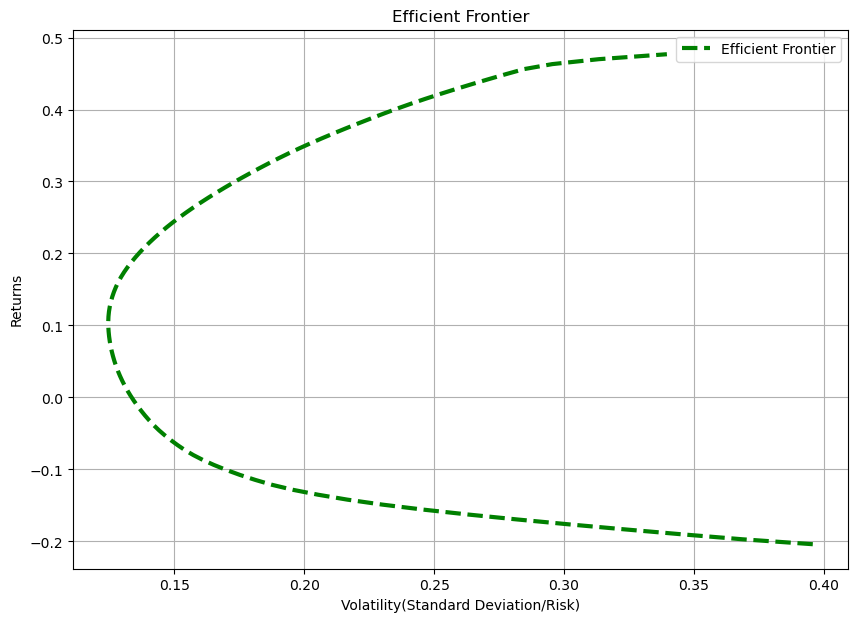

In [20]:
import  matplotlib.pyplot as plt
plt.figure(figsize=(10,7))
plt.plot(efficient_frontier_volatility,target_returns[:len(efficient_frontier_volatility)], 'g--', linewidth=3, label= 'Efficient Frontier')
#plt.scatter()
plt.title('Efficient Frontier')
plt.xlabel('Volatility(Standard Deviation/Risk)')
plt.ylabel('Returns')
plt.legend()
plt.grid(True)
plt.show()

Stage 4:  Adding Risk free + Market Portfolio + capital market line

*   I will be assuming  that the risk free rate is 4% based on my last exercise for simplicity sake

In [21]:
#from fredapi import Fred
#fred = Fred(api_key = '3c4ec30e618f1bd60016581d6e1565a1')
#ten_yr_tr_rate = fred.get_series('GS10')/100

#risk_free_rate = ten_yr_tr_rate.iloc[-1] #latest value
#print(risk_free_rate)

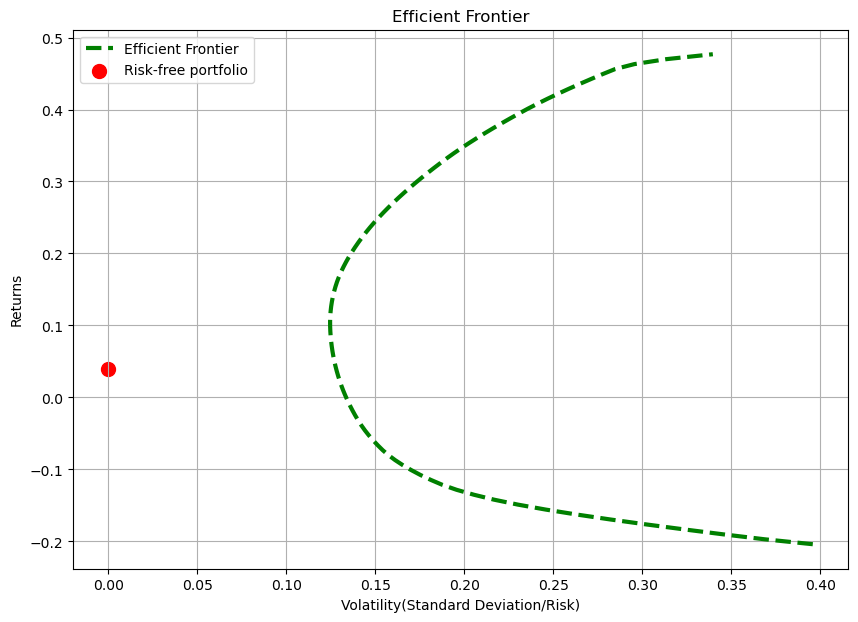

In [22]:
risk_free_rate   = 0.04
plt.figure(figsize=(10,7))
plt.plot(efficient_frontier_volatility,target_returns[:len(efficient_frontier_volatility)], 'g--', linewidth=3, label= 'Efficient Frontier')
#plt.scatter()
plt.scatter(0, risk_free_rate, s=100, color = 'red', marker='o', label= 'Risk-free portfolio')
plt.title('Efficient Frontier')
plt.xlabel('Volatility(Standard Deviation/Risk)')
plt.ylabel('Returns')
plt.legend()
plt.grid(True)
plt.show()

MARKET PORTFOLIO: 

* Maximize the SHARPE RATIO: This ratio measures the excess return relative to risk(volatility)
* Code wise, I have to minimize the negative sharpe ratio because the optimizers minimize by default

In [23]:
def neg_sharpe_ratio(weights, risk_free_rate):
    sharpe_ratio = (expected_portfolio_returns(weights, mean_returns) - risk_free_rate)/portfolio_risk(weights, cov_matrix)
    return -sharpe_ratio

constraints =[{'type': 'eq', 'fun': weights_constraints_0}] # sum of weights = 1,  the only constraints needed here

result = optimize.minimize(neg_sharpe_ratio, initial_weights, args=(risk_free_rate),  method='SLSQP', constraints = constraints, bounds = bounds)

In [24]:
optimal_weights = result.x
market_portfolio_returns = expected_portfolio_returns(optimal_weights, mean_returns)
market_portfolio_volatility = portfolio_risk(optimal_weights, cov_matrix)
max_sharpe_ratio = -result.fun #since the neg sharpe ratio was minimized

Define Capital Market line:
*   Line from Risk-free protfolio through the market portfolio
*   Tangent to the Efficient Frontier 

In [25]:
cml_volatility = np.linspace(0, market_portfolio_volatility*2, 100)
cml_returns = risk_free_rate + max_sharpe_ratio*(cml_volatility)


Add Capital Line to Plot

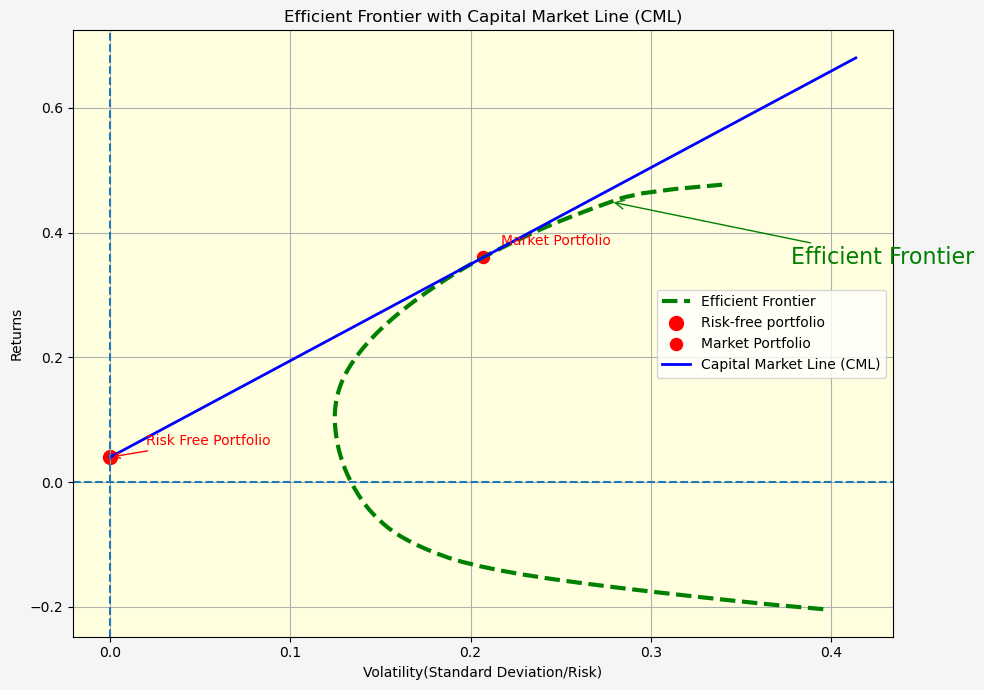

In [26]:
eff_idx=95
cml_idx=30
#Create plot
plt.figure(figsize=(10,7))

#plot the efficient frontier
plt.plot(efficient_frontier_volatility,target_returns[:len(efficient_frontier_volatility)], 'g--', linewidth=3, label= 'Efficient Frontier')
plt.annotate('Efficient Frontier', 
             xy=(efficient_frontier_volatility[eff_idx], target_returns[eff_idx]), 
             xytext=(efficient_frontier_volatility[eff_idx] + 0.1, target_returns[eff_idx] - 0.1),
             arrowprops=dict(arrowstyle="->", color='green'), 
             color='green',fontsize=16)

#Mark and label risk free portfolio
plt.scatter(0, risk_free_rate, s=100, color = 'red', marker='o', label= 'Risk-free portfolio')
plt.annotate('Risk Free Portfolio', xy=(0, risk_free_rate), xytext=(0.02, risk_free_rate+0.02),
             arrowprops=dict(arrowstyle='->', color = 'red'), color='red')

#Mark and label market portfolio
plt.scatter(market_portfolio_volatility, market_portfolio_returns, s=75, marker='o', label = 'Market Portfolio', color='red')
plt.annotate('Market Portfolio', xy=(market_portfolio_volatility, market_portfolio_volatility),
                                     xytext=(market_portfolio_volatility + 0.01, market_portfolio_returns + 0.02),
                                     #arrowprops=dict(arrowstyle='->', color = 'red'),
                                     color='red')

#plot the Capital Market Line (CML)
plt.plot(cml_volatility, cml_returns, 'b-', linewidth=2, label='Capital Market Line (CML)')

plt.axhline(y=0,ls='--')
plt.axvline(x=0,ls='--')

#Add title and labels
plt.title('Efficient Frontier with Capital Market Line (CML)')
plt.xlabel('Volatility(Standard Deviation/Risk)')
plt.ylabel('Returns')
plt.legend()
plt.grid(True)
plt.gcf().set_facecolor('whitesmoke')  # Change figure background
plt.gca().set_facecolor('lightyellow')
plt.tight_layout()
plt.show()